In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Thresholding

## --> Simple Thresholding

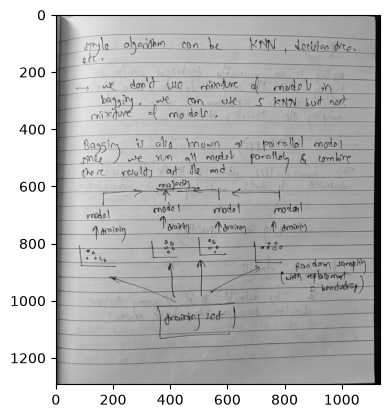

In [3]:
image = cv2.imread("../Images/handwritten.jpeg",0)

plt.imshow(image, cmap="grey")

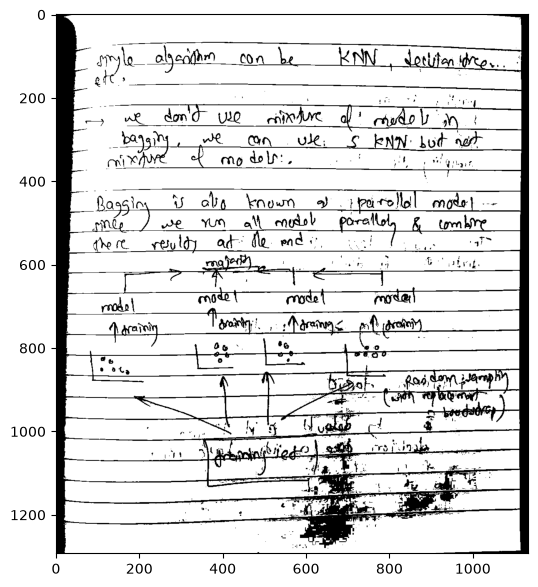

In [4]:
retval, binary = cv2.threshold(image,150,255, cv2.THRESH_BINARY)

plt.figure(figsize=(12,7))

plt.imshow(binary,cmap="grey")
plt.show()

## Adaptive Thresholding

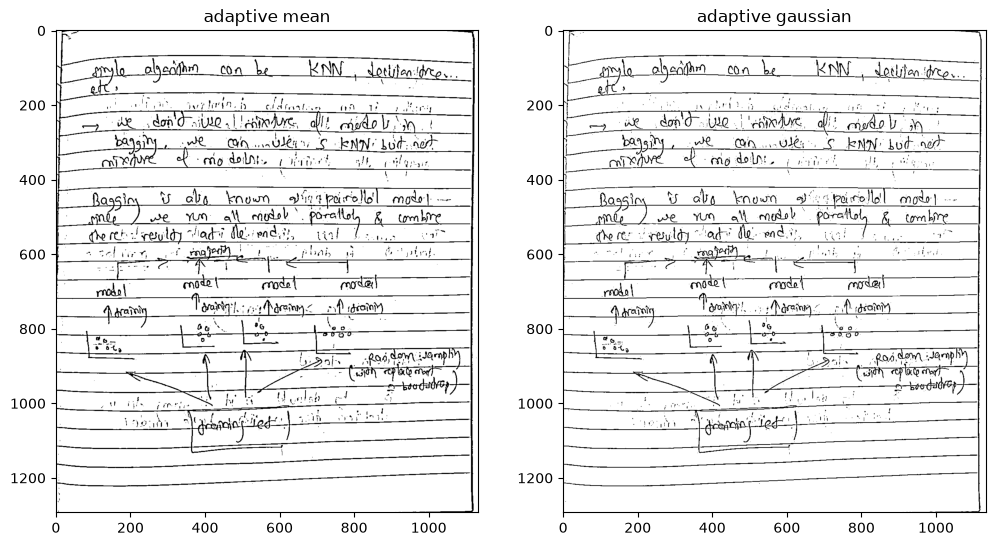

In [7]:
adaptive_m = cv2.adaptiveThreshold(image, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY,11,9)
adaptive_g = cv2.adaptiveThreshold(image, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,11,9)


plt.figure(figsize=(12,7))
plt.subplot(1,2,1)
plt.imshow(adaptive_m, cmap="grey")
plt.title("adaptive mean")

plt.subplot(1,2,2)
plt.imshow(adaptive_g, cmap="grey")
plt.title("adaptive gaussian")

plt.show()


## Kmeans clustering

In [3]:
image = cv2.imread("../Images/shapes.jpg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

pixel_value = image.reshape(-1,3)
#print(pixel_value)
pixel_value = np.float32(pixel_value)


In [5]:
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
k = 3

_, labels, centers = cv2.kmeans(pixel_value, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)


In [7]:
print(labels.shape)
print(centers)

(391876, 1)
[[255.2777   255.2192   255.20657 ]
 [249.43346  114.88152   69.147255]
 [ 70.9147   110.96521  167.68669 ]]


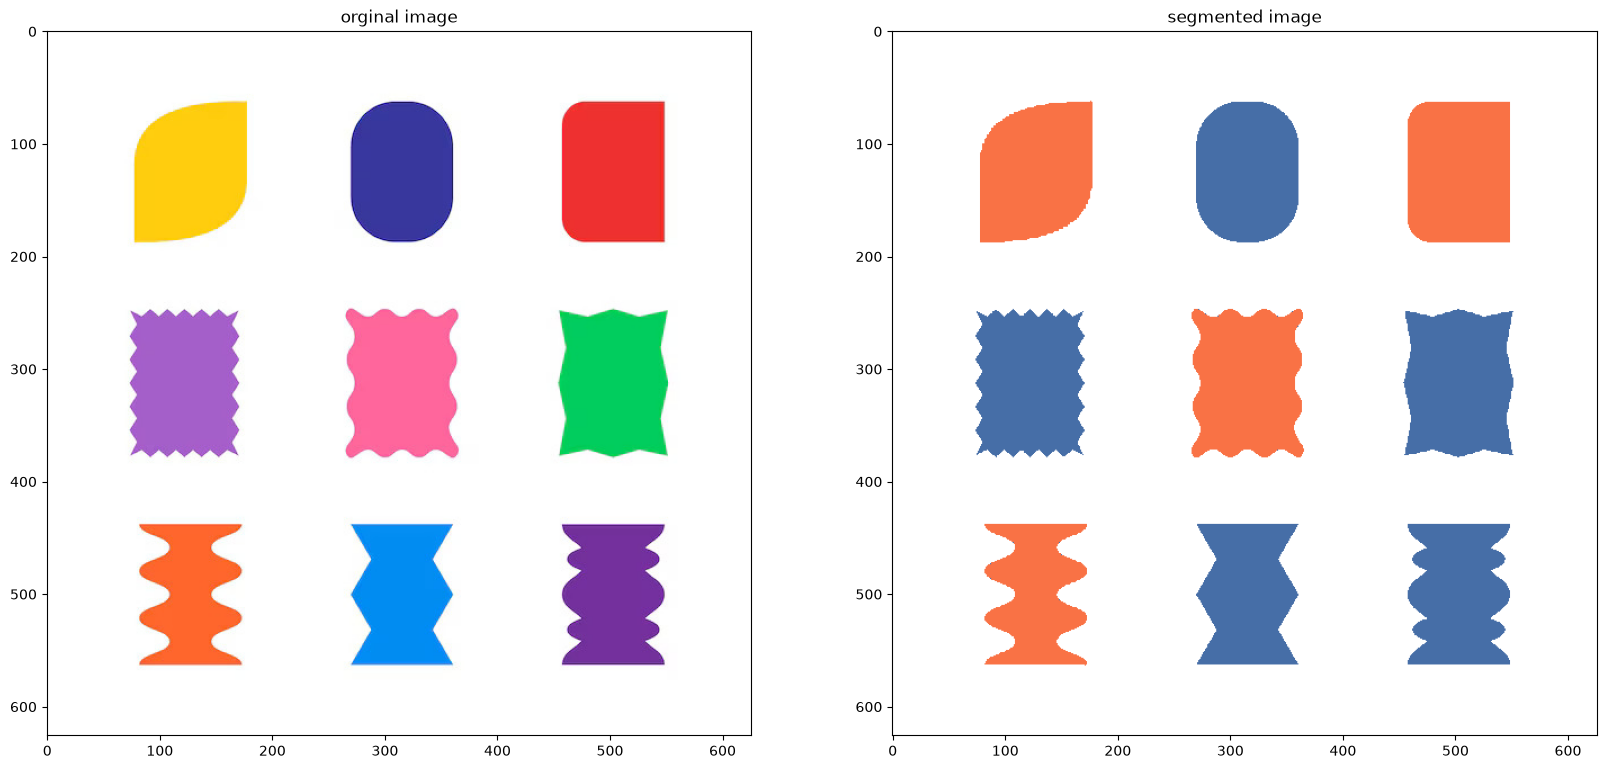

In [8]:
centers = np.uint8(centers)
segmented_image = centers[labels.flatten()]
segmented_image = segmented_image.reshape(image.shape)

plt.figure(figsize=(20,16))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("orginal image")

plt.subplot(1,2,2)
plt.imshow(segmented_image)
plt.title("segmented image")

plt.show()

# Watershed algorithm


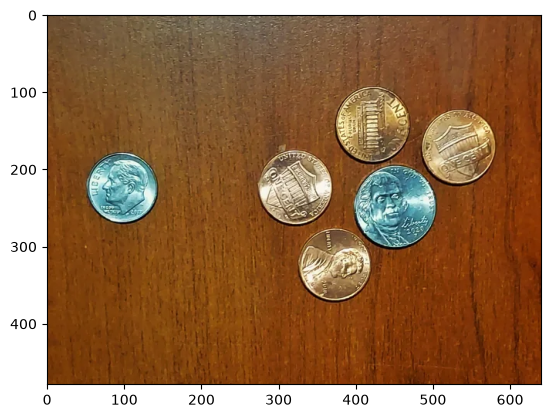

In [9]:
image = cv2.imread("../Images/coin2.jpg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
original_image = image.copy()

plt.imshow(image)

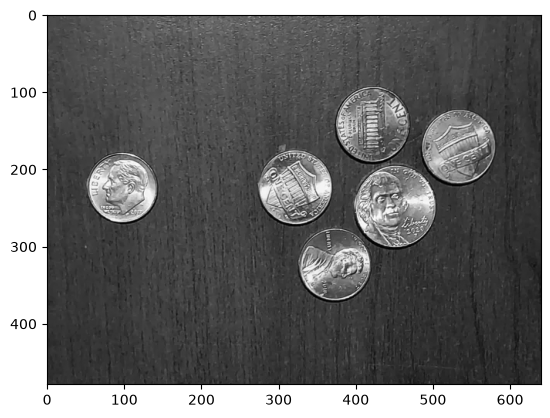

In [10]:
grey = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(grey, cmap="grey")

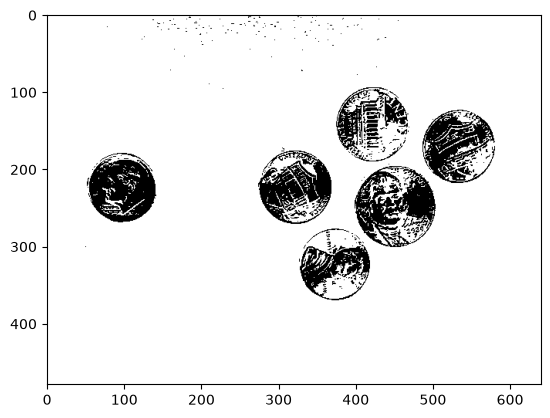

In [11]:
retval, thresh = cv2.threshold(grey, 130, 255, cv2.THRESH_BINARY_INV)

plt.imshow(thresh, cmap="grey")

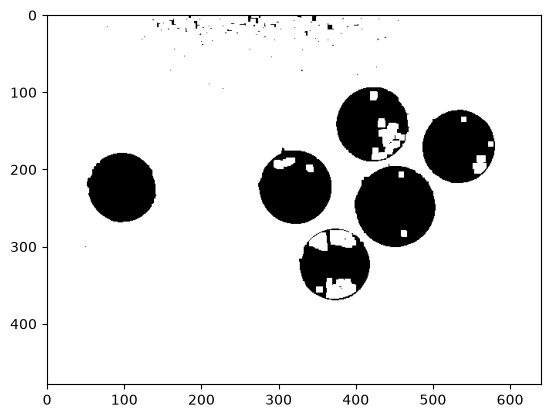

In [12]:
# reducing noise

kernel = np.ones((3,3),np.uint8)

opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=3)

plt.imshow(opening, cmap="grey")

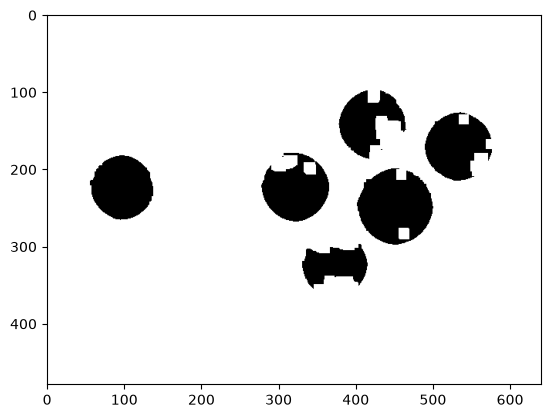

In [13]:
sure_bg = cv2.dilate(opening, kernel, iterations=3)
plt.imshow(sure_bg, cmap="grey")

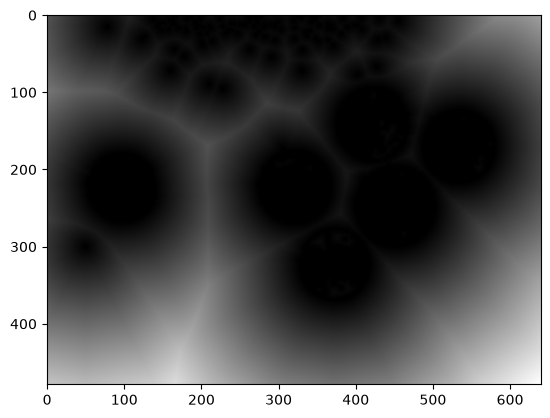

In [14]:
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)

plt.imshow(dist_transform, cmap="grey")

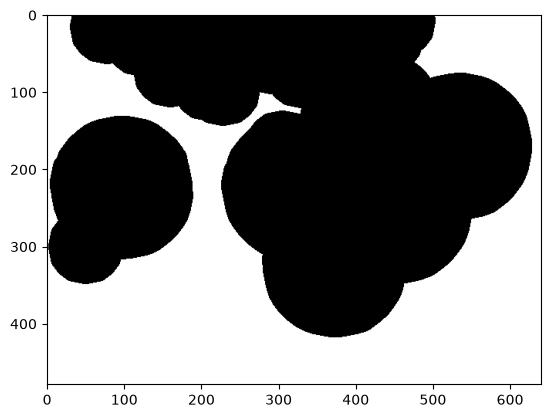

In [16]:
_, sure_fg = cv2.threshold(dist_transform, 0.2*dist_transform.max(),255, 0)

sure_fg = np.uint8(sure_fg)

plt.imshow(sure_fg, cmap="grey")

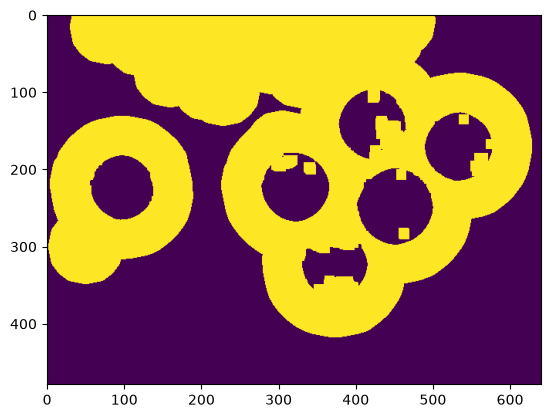

In [17]:
unknown = cv2.subtract(sure_bg , sure_fg)

plt.imshow(unknown)

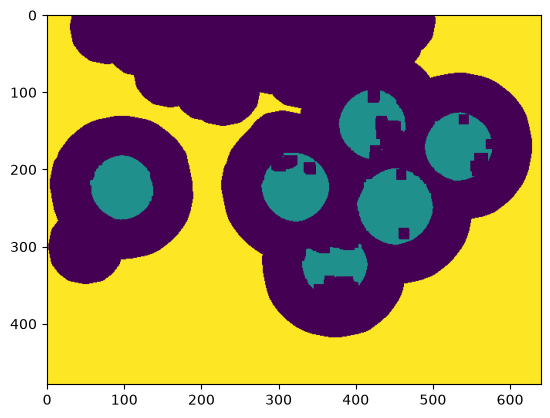

In [18]:
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown== 255] = 0

plt.imshow(markers)

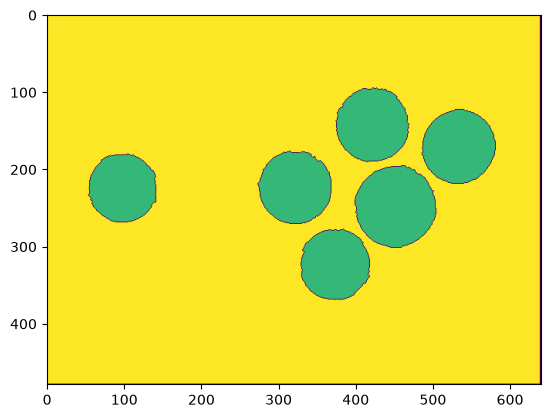

In [19]:
markers = cv2.watershed(image, markers)
plt.imshow(markers)

In [21]:
coin_mask = np.zeros_like(grey)

#print(grey.shape)
#print(coin_mask.shape)

unique_labels = np.unique(markers)

instance_number = 1
font = cv2.FONT_HERSHEY_COMPLEX

for label in unique_labels:
    if label==0 or label==-1:
        continue
    mask = np.uint8(markers == label)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    for contour in contours:
        area = cv2.contourArea(contour)
        perimeter =cv2.arcLength(contour,True)
        
        if perimeter == 0:
            continue
        
        circularity = 4*np.pi*(area/(perimeter**2))
        
        if 0.7<circularity<1.2 and area>1000:
            cv2.drawContours(original_image, [contour], -1, (0,255,0), 2)
            x,y,w,h = cv2.boundingRect(contour)
            cv2.putText(original_image, f'coin{instance_number}',(x,y-10), font, 0.6, (255,0,0), 2)
            coin_mask = cv2.bitwise_or(coin_mask, mask)
            cv2.rectangle(original_image,(x-5,y-5),(x+w+5,y+h+5), (160,150,250), 2)
            instance_number += 1

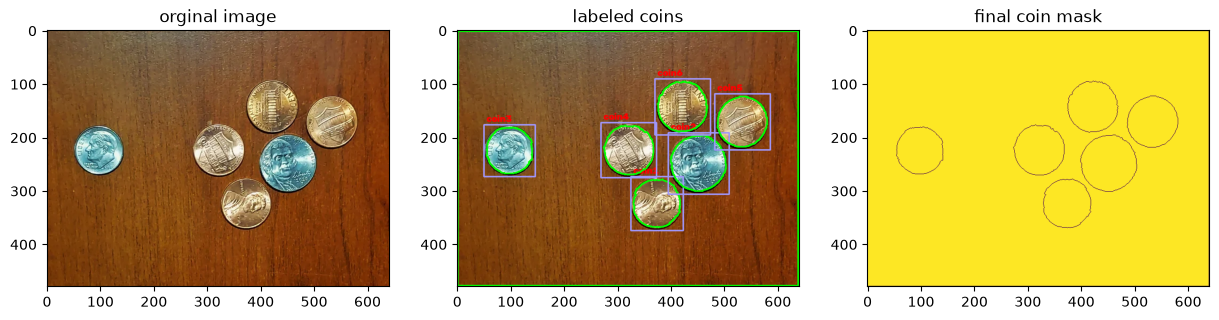

In [22]:
plt.figure(figsize=(15,10))

plt.subplot(1,3,1)
plt.imshow(image)
plt.title("orginal image")

plt.subplot(1,3,2)
plt.imshow(original_image)
plt.title("labeled coins")

plt.subplot(1,3,3)
plt.imshow(coin_mask)
plt.title("final coin mask")

plt.show()